# EXP_08. ¿El verdor de una parcela, comparado con el de sus vecinas, explica lo que el territorio no explica?

**CRISP-DM: regresamos a entender y preparar los datos antes de modelar.** Seis rondas y la
séptima en curso buscaron información satelital que mejorara la referencia territorial
**MIX** (50 % media municipal + 50 % IDW). Ninguna fue adoptada. Este cuaderno no propone
otra variable más con un nombre nuevo: primero pregunta **por qué** ha sido tan difícil y
solo después propone una hipótesis que responde a ese diagnóstico.

| Bloque | Pregunta | Respuesta corta (se comprueba abajo) |
| --- | --- | --- |
| A | ¿Dónde está el error que queda? | Sobre todo en Chignahuapan: variación entre parcelas del mismo municipio. |
| B | ¿Alguna de las ~600 variables ya construidas distingue parcelas dentro del municipio? | Ninguna supera lo esperable por azar. Buscar más agregados tiene bajo retorno. |
| C | ¿Qué estructura tiene ese error? | Dependencia espacial **de corto alcance (≈500 m)**. MIX ya la aprovecha; afinarlo empeora. |
| D | Hipótesis H8 | Comparar la curva de verdor de cada parcela con la de sus vecinas a <1 km cancela fecha, clima y entorno comunes. Lo que queda podría ser propio de la parcela. |
| E | ¿Mejora a MIX fuera de muestra? | Sí, poco (≈0.005 t/ha de RMSE), con nulo por permutación, réplica Sentinel-2 y concentración reportados. |

**Estado:** exploratorio con elementos predeclarados. La variable y el radio se eligieron
**después** de mirar etiquetas. Por eso el cuaderno incluye una versión que repite esa
selección dentro de cada entrenamiento y dos nulos por permutación. **No genera las 59
predicciones de entrega.** Ejecutarlo hace ajustes nuevos (sección 9: presupuesto).

## Cómo leer este cuaderno

Formato del proyecto: **pregunta → comprobación → resultado → decisión y límite**. Cada
número que aparece en el texto se comprueba con un `assert` en el código. Si una ejecución
futura no coincide, el cuaderno se detiene en lugar de mostrar texto desactualizado.

### Registro de decisiones: de dónde sale cada elección

La última columna es la más importante para juzgar el resultado: dice si la elección se
hizo **viendo rendimientos**. Una elección hecha así no invalida el resultado, pero exige
controles adicionales (secciones 8 y 9).

| # | Decisión | Valor | Por qué | ¿Se eligió viendo etiquetas? |
| --- | --- | --- | --- | --- |
| 1 | Fuente de la curva | NDVI promedio Planet 2025 | Sensor más denso del dataset (mediana ≈94 capturas por parcela en el ciclo). | No |
| 2 | Calidad de captura | Nubosidad ≤20 % | Umbral ya usado en la exploración inicial y el diagnóstico del equipo. No se probaron otros umbrales. | No |
| 3 | Suavizado | Mediana diaria, luego mediana móvil centrada de 15 días (±7), mínimo 3 días | Misma ventana que EXP_06. Tolera capturas aisladas. | No |
| 4 | Línea base | Mediana de abril–mayo (día 91–150) | Las curvas muestran suelo antes de la emergencia: el mínimo anual cae en abril–mayo (auditoría del equipo). | No |
| 5 | Inicio y fin del verdor | Cruces del 50 % de la amplitud | Convención estándar de fenología satelital (Jönsson y Eklundh, 2004). | No |
| 6 | Resumen de la curva | Integral sobre la base entre esos cruces | Duración del área verde, aproximación clásica a la capacidad fotosintética de la temporada (Rasmussen, 1992). | **Sí**: elegida entre 16 descriptores. Se controla en la sección 8 (C2). |
| 7 | Contraste | Valor de la parcela − mediana de sus vecinas | Diferencias espaciales: vecinas comparten clima, fechas, entorno y probablemente manejo (Druckenmiller y Hsiang, 2018). | La idea, no; el resultado se vio después. |
| 8 | Radio | 1 km, ≥2 vecinas, entre las 197 parcelas | El variograma (sección C) muestra correlación hasta ≈500 m; 1 km asegura vecinas. | **Sí**: 1 km y 2 km se vieron juntos; 500 m después, como sensibilidad. |
| 9 | Uso de las 59 sin etiqueta | Solo como vecinas (su X) | Su información satelital fue entregada; nunca se usan sus rendimientos (no existen). | No |
| 10 | Modelo | MIX + β·z, β con penalización fija α=10 | Comparar directamente con el campeón. Sin búsqueda de hiperparámetros: afinar MIX empeoró (sección C). | α no. MIX como base sí, por ser la mejor referencia conocida. |
| 11 | Residuos para estimar β | Validación cruzada interna (particiones históricas) | El IDW incluiría a la propia parcela a distancia 0: su residuo dentro de muestra sería casi cero. | No |
| 12 | Parcela sin vecinas | Sin corrección (queda MIX) | No se inventa contraste. | No |
| 13 | Réplica con Sentinel-2 | Misma receta, ventana 21 días, mínimo 2 | **Predeclarada por escrito antes de calcularla** (8 oct 2026, 12:09 h CDMX). | Receta no; criterio fijado antes. |
| 14 | Curva hasta diciembre | El fin del verdor puede caer en noviembre | La senescencia ocurre en oct–nov. Usar nov–dic es una decisión del equipo (§12). Se reporta también la versión cortada al 31 de octubre. | No |

## 1. Preparación y trazabilidad

El cuaderno necesita la carpeta del proyecto con tres insumos identificados por SHA-256.
Los dos primeros hashes son los mismos que publica el plan de EXP_07.

| Insumo | Uso |
| --- | --- |
| `data/raw/DataSet.zip` | Etiquetas, polígonos, Planet y Sentinel-2 originales |
| `data/validacion_03/particiones_externas.csv` / `particiones_internas.csv` | Las mismas 50 particiones exteriores y 200 interiores de todas las rondas |
| `data/referencias/variables_v0_197.csv` / `postciclo_PENDIENTE_197.csv` | Solo para el barrido de la sección B: todo lo que el equipo ya construyó |

**Colab:** subir la carpeta `agrocebada-uv` (o al menos esos cinco archivos con la misma
estructura) y escribir su ruta en `RUTA_PROYECTO`. Necesita `pyshp`, `shapely` y `pyproj`.

In [1]:
RUTA_PROYECTO = None   # p. ej. "/content/agrocebada-uv"; None = buscar desde la carpeta actual
N_PERM_C1 = 200        # permutaciones del nulo de la sección 9 (C1)
N_PERM_C2 = 100        # permutaciones del nulo con selección (C2); es la celda más lenta
SEMILLA = 20261008

import hashlib, io, platform, time, warnings, zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapefile
from shapely.geometry import shape
from shapely.ops import transform
from pyproj import Transformer
from scipy.stats import spearmanr
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # GP: avisos de cotas, no errores
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def raiz_proyecto():
    if RUTA_PROYECTO:
        return Path(RUTA_PROYECTO).resolve()
    actual = Path.cwd().resolve()
    for p in [actual, *actual.parents]:
        if (p / "pyproject.toml").exists() and (p / "data" / "raw" / "DataSet.zip").exists():
            return p
    raise FileNotFoundError("No encuentro la carpeta del proyecto; define RUTA_PROYECTO.")


RAIZ = raiz_proyecto()
INSUMOS = {
    "data/raw/DataSet.zip": "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5",
    "data/validacion_03/particiones_externas.csv": "02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec",
    "data/validacion_03/particiones_internas.csv": "a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a",
    "data/referencias/variables_v0_197.csv": "62e39ba23fb33f8834e92943f9714fea38aa731da079e0431d707aab13151595",
    "data/referencias/postciclo_PENDIENTE_197.csv": "7a407ddcb87e702d3cc52dc694560006fa03012cdd7acb2959d8774fa9c54fa4",
}
filas = []
for rel, esperado in INSUMOS.items():
    datos = (RAIZ / rel).read_bytes()
    obtenido = hashlib.sha256(datos).hexdigest()
    if obtenido != esperado:
        raise ValueError(f"SHA-256 distinto en {rel}: no se continúa")
    filas.append({"insumo": rel, "bytes": len(datos), "sha256": obtenido[:16] + "…"})
display(pd.DataFrame(filas))
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| ejecución UTC", datetime.now(timezone.utc).isoformat(timespec="seconds"))
T0 = time.time()

,insumo,bytes,sha256
0,data/raw/DataSet.zip,29687194,d74dbaba1764e026…
1,data/validacion_03/particiones_externas.csv,175295,02d07dfcdb8064a4…
2,data/validacion_03/particiones_internas.csv,601731,a35412fda33fcea7…
3,data/referencias/variables_v0_197.csv,977024,62e39ba23fb33f88…
4,data/referencias/postciclo_PENDIENTE_197.csv,185770,7a407ddcb87e702d…


Python 3.13.13 | pandas 2.2.3 | numpy 2.4.4 | ejecución UTC 2026-10-08T18:25:04+00:00


### Lectura de los originales

Una fila de la tabla final es una parcela. Las coordenadas son centroides en UTM 14N
(EPSG:32614), la misma receta que usa MIX en todas las rondas. Se comprueba abajo que
reproducen MIX exactamente.

In [2]:
Z = zipfile.ZipFile(RAIZ / "data/raw/DataSet.zip")
PREF = "DATASET_RETO_AGRO_2026/"
etiquetas = pd.read_csv(Z.open(PREF + "ID_area_rendimiento_70_30_Reto_AgroCebada.csv"),
                        encoding="utf-8-sig").iloc[:, :4]

interno = zipfile.ZipFile(io.BytesIO(Z.read(PREF + "Parcelas_Reto_AGC_CONJUNTO_70_30.zip")))
partes = {n.rsplit(".", 1)[-1].lower(): n for n in interno.namelist() if n.lower().endswith((".shp", ".dbf", ".shx"))}
lector = shapefile.Reader(shp=io.BytesIO(interno.read(partes["shp"])), dbf=io.BytesIO(interno.read(partes["dbf"])),
                          shx=io.BytesIO(interno.read(partes["shx"])), encoding="utf-8")
a_utm = Transformer.from_crs(4326, 32614, always_xy=True).transform
cat = []
for reg, forma in zip(lector.records(), lector.shapes()):
    g = transform(lambda x, y, z=None: a_utm(x, y), shape(forma.__geo_interface__))
    cat.append({"ID_POLIGONO": reg["ID_POLIGON"], "Municipio": reg["Municipio"], "Cultivo": reg["Cultivo"],
                "x_m": g.centroid.x, "y_m": g.centroid.y})
T = pd.DataFrame(cat).merge(etiquetas, on="ID_POLIGONO", validate="one_to_one").set_index("ID_POLIGONO").sort_index()
T = T.rename(columns={"RENDIMIENTO_T_HA": "y"})
assert len(T) == 197 and T.y.notna().sum() == 138
assert set(T.index[T.y.isna()]) == set(T.index[T.CONJUNTO.eq("PREDICCION")])
L = T[T.y.notna()].copy()            # 138 etiquetadas
OCULTAS = T.index[T.y.isna()]        # 59 sin etiqueta: solo X

pro = pd.read_csv(Z.open(PREF + "Conjunto_datos_PRO_AgroCebada.csv"), encoding="utf-8-sig")
bas = pd.read_csv(Z.open(PREF + "Conjunto_datos_BASICO_AgroCebada2026.csv"), encoding="utf-8-sig")
for d in (pro, bas):
    d["fecha"] = pd.to_datetime(d.fecha_captura, format="%d/%m/%Y", errors="raise")
assert set(pro.sensor) == {"Planet"} and pro.ID_POLIGONO.nunique() == 197
assert not pro.duplicated(["ID_POLIGONO", "fecha", "sensor"]).any()

EXT = pd.read_csv(RAIZ / "data/validacion_03/particiones_externas.csv")
INT = pd.read_csv(RAIZ / "data/validacion_03/particiones_internas.csv")
assert len(EXT) == 6900 and len(INT) == 22080
print(T.groupby("Municipio").agg(parcelas=("y", "size"), etiquetadas=("y", "count")).to_string())

                               parcelas  etiquetadas
Municipio                                           
Almoloya                             14           10
Apan                                  1            1
Calpulalpan                          44           30
Chignahuapan                        100           71
Cuautepec de Hinojosa                 9            5
Emiliano Zapata                       3            3
Nanacamilpa de Mariano Arista         2            1
Singuilucan                          23           16
Tepeapulco                            1            1


## 2. Bloque A — ¿Dónde está el error que queda?

**Pregunta.** Antes de buscar información nueva conviene saber qué error queremos reducir.

**Comprobación.** Reconstruimos MUN y MIX con la receta histórica (k=20, potencia 2,
piso 1 m) sobre las 50 particiones. Deben coincidir con las cifras publicadas:
**MIX 0.4938 (FULL138) y 0.4872 (SEEN135)**. Después repartimos su error cuadrático
por municipio.

In [3]:
def splits():
    for (r, f), g in EXT.groupby(["repeticion", "pliegue"]):
        yield int(r), int(f), g.loc[g.rol.eq("entrenamiento"), "ID_POLIGONO"].to_numpy(), g.loc[g.rol.eq("validacion"), "ID_POLIGONO"].to_numpy()


SPLITS = list(splits())
assert len(SPLITS) == 50


def mun_pred(a, t):
    # Media municipal aprendida en a; municipio no visto -> media global de a.
    return t.Municipio.map(a.groupby("Municipio").y.mean()).fillna(a.y.mean()).to_numpy()


def idw(a, t, k=20, p=2):
    d = np.linalg.norm(t[["x_m", "y_m"]].to_numpy()[:, None] - a[["x_m", "y_m"]].to_numpy()[None], axis=2)
    idx = np.argsort(d, axis=1)[:, :min(k, len(a))]
    w = 1 / np.maximum(np.take_along_axis(d, idx, 1), 1.0) ** p
    w /= w.sum(1, keepdims=True)
    return (w * a.y.to_numpy()[idx]).sum(1)


def mix(a, t):
    return 0.5 * mun_pred(a, t) + 0.5 * idw(a, t)


def evaluar(modelos):
    # modelos: {nombre: f(r, f, a, t) -> predicciones}. Una fila por modelo/ID/repetición.
    filas = []
    for r, f, tr, va in SPLITS:
        a, t = L.loc[tr], L.loc[va]
        visto = t.Municipio.isin(set(a.Municipio)).to_numpy()
        for nombre, fn in modelos.items():
            p = np.asarray(fn(r, f, a, t), float)
            assert p.shape == (len(t),) and np.isfinite(p).all()
            filas.append(pd.DataFrame({"modelo": nombre, "rep": r, "pliegue": f, "ID_POLIGONO": va,
                                       "obs": t.y.to_numpy(), "pred": p, "visto": visto, "Municipio": t.Municipio.to_numpy()}))
    return pd.concat(filas, ignore_index=True)


def resumen(oof, ref="MIX"):
    out = []
    for esc, o in [("SEEN135", oof[oof.visto]), ("FULL138", oof)]:
        e = o.assign(e=o.pred - o.obs)
        rmse_rep = e.groupby(["modelo", "rep"]).e.apply(lambda s: np.sqrt((s ** 2).mean())).unstack()
        mae_rep = e.groupby(["modelo", "rep"]).e.apply(lambda s: s.abs().mean()).unstack()
        for m, g in e.groupby("modelo"):
            ch = g.Municipio.eq("Chignahuapan")
            out.append({"escenario": esc, "modelo": m, "n_oof": len(g),
                        "RMSE": np.sqrt((g.e ** 2).mean()), "MAE": g.e.abs().mean(),
                        "R2": 1 - (g.e ** 2).sum() / ((g.obs - g.obs.mean()) ** 2).sum(),
                        f"reps RMSE<{ref}": int((rmse_rep.loc[m] < rmse_rep.loc[ref]).sum()) if ref in rmse_rep.index else np.nan,
                        f"reps MAE<{ref}": int((mae_rep.loc[m] < mae_rep.loc[ref]).sum()) if ref in mae_rep.index else np.nan,
                        "RMSE Chignahuapan": np.sqrt((g.e[ch] ** 2).mean()), "RMSE resto": np.sqrt((g.e[~ch] ** 2).mean())})
    return pd.DataFrame(out).set_index(["escenario", "modelo"])


oof_ref = evaluar({"MUN": lambda r, f, a, t: mun_pred(a, t), "MIX": lambda r, f, a, t: mix(a, t)})
R_REF = resumen(oof_ref)
assert abs(R_REF.loc[("FULL138", "MIX"), "RMSE"] - 0.49384524493208876) < 1e-9
assert abs(R_REF.loc[("SEEN135", "MIX"), "RMSE"] - 0.48719651492001237) < 1e-9
display(R_REF.round(4))

e = oof_ref[oof_ref.modelo.eq("MIX") & oof_ref.visto].assign(se=lambda d: (d.pred - d.obs) ** 2)
reparto = e.groupby("Municipio").agg(oof=("se", "size"), SSE=("se", "sum")).assign(
    parte_del_error=lambda d: d.SSE / d.SSE.sum(), parte_de_las_parcelas=lambda d: d.oof / d.oof.sum())
display(reparto.sort_values("SSE", ascending=False).round(3))
PARTE_CHIG = reparto.loc["Chignahuapan", "parte_del_error"]
assert 0.72 < PARTE_CHIG < 0.80

n_oof    RMSE     MAE      R2  reps RMSE<MIX  reps MAE<MIX  RMSE Chignahuapan  RMSE resto
escenario modelo                                                                                           
SEEN135   MIX      1350  0.4872  0.3342  0.6660              0             0             0.5736      0.3683
          MUN      1350  0.4934  0.3213  0.6575              1            10             0.5902      0.3565
FULL138   MIX      1380  0.4938  0.3417  0.6609              0             0             0.5736      0.3920
          MUN      1380  0.5118  0.3354  0.6359              0            10             0.5902      0.4127

,oof,SSE,parte_del_error,parte_de_las_parcelas
Municipio,,,,
Chignahuapan,710,233.624,0.729,0.526
Calpulalpan,300,48.317,0.151,0.222
Singuilucan,160,31.314,0.098,0.119
Cuautepec de Hinojosa,50,3.389,0.011,0.037
Almoloya,100,3.219,0.010,0.074
Emiliano Zapata,30,0.573,0.002,0.022


**Resultado.** MIX se reproduce al décimo decimal. **Chignahuapan tiene el 53 % de las
predicciones evaluadas, pero el 73 % del error cuadrático de MIX.**
29 de las 59 parcelas ocultas también están ahí. Cualquier mejora real tiene que
distinguir parcelas *dentro* de un municipio, y sobre todo dentro de Chignahuapan.

**Una nota sobre las etiquetas, solo descriptiva.** La precisión del rendimiento cambia por
territorio: Calpulalpan y los municipios con grafía `Cebada` solo usan múltiplos de 0.5;
Singuilucan, un decimal; Chignahuapan, Almoloya y Cuautepec, dos. El equipo ya documentó que
esto sugiere procedencias de captura distintas y decidió **no** usar la grafía como predictor.
Este cuaderno respeta esa decisión: la tabla siguiente explica por qué el error se reparte
así, no alimenta ningún modelo.

In [4]:
def decimales(v):
    for k in (0.5, 0.1, 0.01):
        if np.isclose(v / k, round(v / k)):
            return {0.5: "múltiplo de 0.5", 0.1: "un decimal", 0.01: "dos decimales"}[k]
    return "más"


precision = pd.crosstab(L.Municipio, L.y.map(decimales))
precision["media"] = L.groupby("Municipio").y.mean().round(2)
precision["desv. dentro"] = L.groupby("Municipio").y.std().round(2)
display(precision)

y,dos decimales,múltiplo de 0.5,un decimal,media,desv. dentro
Municipio,,,,,
Almoloya,10,0,0,4.52,0.19
Apan,0,1,0,3.00,NaN
Calpulalpan,0,30,0,3.00,0.37
Chignahuapan,65,1,5,4.48,0.58
Cuautepec de Hinojosa,4,0,1,4.60,0.15
Emiliano Zapata,0,3,0,3.50,0.00
Nanacamilpa de Mariano Arista,0,1,0,2.50,NaN
Singuilucan,0,9,7,3.08,0.43
Tepeapulco,1,0,0,4.45,NaN


## 3. Bloque B — ¿Alguna variable ya construida distingue parcelas dentro del municipio?

**Por qué esta pregunta.** Cada ronda probó una o pocas variables y obtuvo un resultado
pequeño o nulo. Ronda por ronda es difícil saber si falló la receta o si casi no hay señal
que encontrar. Aquí miramos todo a la vez.

**Comprobación.** Tomamos todas las columnas numéricas de la tabla v0 (ciclo, historia
2022–2024, clima, topografía) y de postciclo (nov–dic), más el logaritmo del área. Para
cada una calculamos la correlación de rangos **dentro del municipio** con el rendimiento:
restamos a rangos de X y de y su media municipal. Con cientos de variables, alguna saldrá
alta por azar. Por eso comparamos el máximo observado con el **máximo que se obtiene al
permutar los rendimientos dentro de cada municipio** (1,000 veces). Este nulo conserva la
estructura territorial y la correlación entre variables.

**Límite.** Es un barrido univariado y lineal en rangos. No descarta interacciones ni
señales repartidas en muchas variables débiles. Pero esas alternativas ya se exploraron
en E1–E4 y en el contraste Ridge/HGB, sin éxito.

Variables en el barrido: 619


{'mediana': np.float64(0.259), 'p95': np.float64(0.329), 'observado': np.float64(0.251), 'p_valor': np.float64(0.603)}


,r dentro del municipio
C_PL_evi_pixmin,0.251
C_S2_dswi5_doy_pico_prom,0.245
H2022_S2_savi_n,-0.239
H2022_S2_ndwi_n,-0.239
H2022_S2_ndvi_n,-0.239
H2022_S2_msi_n,-0.239
H2022_S2_lai_n,-0.239
H2022_S2_evi_n,-0.239
C_PL_msavi_pixmin,0.237
C_PL_ndvi_mediana,-0.230


Variable de EXP_07 (dispersión NDVI Planet): 0.079


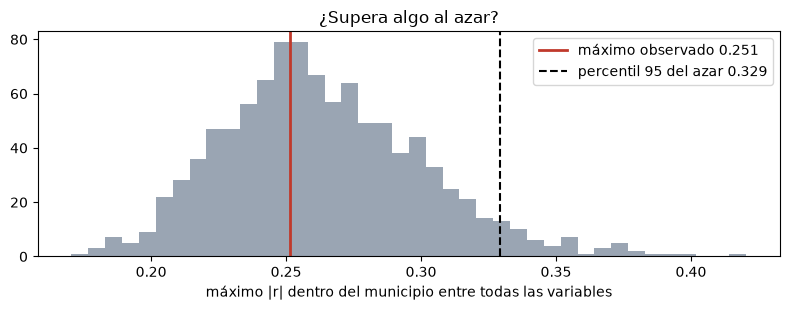

In [5]:
V = pd.read_csv(RAIZ / "data/referencias/variables_v0_197.csv").set_index("ID_POLIGONO")
P = pd.read_csv(RAIZ / "data/referencias/postciclo_PENDIENTE_197.csv").set_index("ID_POLIGONO")
NO_MEDICION = {"x_m", "y_m", "longitude", "latitude", "area_geom_ha", "AREA_HA", "dif_area_pct",
               "geom_valida_original", "geom_vertices_repetidos"}
X = pd.concat([V.select_dtypes("number").drop(columns=list(NO_MEDICION), errors="ignore"),
               P.select_dtypes("number")], axis=1)
X["log_area_ha"] = np.log(T.AREA_HA)
X = X.loc[:, (X.loc[L.index].notna().mean() > 0.9) & (X.loc[L.index].std() > 0)]
print("Variables en el barrido:", X.shape[1])

mun = L.Municipio
grupos = [np.flatnonzero(mun.to_numpy() == m) for m in mun.unique()]


def centrar(A):
    A = np.asarray(A, float).copy()
    for g in grupos:
        A[g] -= A[g].mean(axis=0)
    return A


Xr = X.loc[L.index].rank().fillna(X.loc[L.index].rank().median())
Xc = centrar(Xr.to_numpy())
Xc = (Xc - Xc.mean(0)) / Xc.std(0, ddof=1)


def corr_dentro(yv):
    yc = centrar(pd.Series(yv).rank().to_numpy()[:, None])[:, 0]
    yc = (yc - yc.mean()) / yc.std(ddof=1)
    return Xc.T @ yc / (len(yc) - 1)


r_obs = pd.Series(corr_dentro(L.y.to_numpy()), index=X.columns)
rng = np.random.default_rng(SEMILLA)
yv = L.y.to_numpy()
maximos = []
for _ in range(1000):
    yp = yv.copy()
    for g in grupos:
        yp[g] = rng.permutation(yp[g])
    maximos.append(np.abs(corr_dentro(yp)).max())
maximos = np.array(maximos)
NULO_B = {"mediana": np.median(maximos), "p95": np.quantile(maximos, 0.95), "observado": r_obs.abs().max(),
          "p_valor": (maximos >= r_obs.abs().max()).mean()}
print({k: round(v, 3) for k, v in NULO_B.items()})
top = r_obs.reindex(r_obs.abs().sort_values(ascending=False).index).head(12).round(3).to_frame("r dentro del municipio")
display(top)
print("Variable de EXP_07 (dispersión NDVI Planet):", round(r_obs.get("C_PL_ndvi_std_media", np.nan), 3))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(maximos, bins=40, color="#9aa5b3")
ax.axvline(NULO_B["observado"], color="#c0392b", lw=2, label=f"máximo observado {NULO_B['observado']:.3f}")
ax.axvline(NULO_B["p95"], color="k", ls="--", label=f"percentil 95 del azar {NULO_B['p95']:.3f}")
ax.set_xlabel("máximo |r| dentro del municipio entre todas las variables"); ax.legend(); ax.set_title("¿Supera algo al azar?")
plt.tight_layout(); plt.show()
assert NULO_B["p_valor"] > 0.3   # el máximo observado es típico del azar

**Resultado.** La variable más asociada dentro del municipio tiene |r| ≈ 0.25. Al permutar
rendimientos, el máximo esperado por azar es de ese mismo tamaño: el observado queda cerca
de la mediana del nulo, lejos del percentil 95. **Con 138 parcelas, ninguna de las cientos
de variables ya construidas muestra señal individual distinguible del azar dentro del
municipio.** La dispersión de EXP_07 tiene r ≈ 0.08. Ese tamaño anticipa un resultado nulo
en la ronda en curso.

**Decisión.** Esto explica en buena parte las seis rondas: no fallaron por mala ejecución.
Buscaban en un espacio donde la evidencia es compatible con *ninguna señal individual*.
**Dejar de abrir nuevas familias de agregados** (otro índice, otra ventana, otra
estadística) tiene ahora fundamento cuantitativo. Si queda información, hay que buscarla
con otra *representación*, no con más columnas del mismo tipo.

## 4. Bloque C — ¿Qué estructura tiene el error que queda?

**Pregunta.** Si las variables no explican el residuo municipal, ¿se parece al de las
parcelas vecinas?

**Comprobación.** Semivarianza de los residuos respecto de la media municipal, por
distancia, solo entre pares del **mismo** municipio. Si a corta distancia la semivarianza
es menor que la meseta, parcelas cercanas comparten algo: suelo, microclima, productor,
fecha de siembra.

In [6]:
res_mun = L.y - L.groupby("Municipio").y.transform("mean")
xy = L[["x_m", "y_m"]].to_numpy()
D = np.linalg.norm(xy[:, None] - xy[None], axis=2)
mismo = L.Municipio.to_numpy()[:, None] == L.Municipio.to_numpy()[None]
iu = np.triu_indices(len(L), 1)
gam = 0.5 * (res_mun.to_numpy()[:, None] - res_mun.to_numpy()[None]) ** 2
cortes = [0, 250, 500, 1000, 2000, 4000, 8000]
filas = []
for zona, extra in [("todas", np.ones_like(mismo)), ("Chignahuapan", (L.Municipio.eq("Chignahuapan").to_numpy()[:, None]) & (L.Municipio.eq("Chignahuapan").to_numpy()[None]))]:
    for a_, b_ in zip(cortes[:-1], cortes[1:]):
        m = ((D >= a_) & (D < b_) & mismo & extra)[iu]
        filas.append({"zona": zona, "distancia_m": f"{a_}–{b_}", "pares": int(m.sum()), "semivarianza": gam[iu][m].mean()})
vario = pd.DataFrame(filas)
display(vario.pivot(index="distancia_m", columns="zona", values=["pares", "semivarianza"]).reindex([f"{a}–{b}" for a, b in zip(cortes[:-1], cortes[1:])]).round(3))

ch = L.Municipio.eq("Chignahuapan").to_numpy()
Dc = D[np.ix_(ch, ch)] + np.eye(ch.sum()) * 1e12
vecino = Dc.argmin(1)
rc = res_mun.to_numpy()[ch]
R_VECINO = np.corrcoef(rc, rc[vecino])[0, 1]
print(f"Chignahuapan: correlación del residuo con el de su vecina más cercana = {R_VECINO:.2f}; "
      f"distancia mediana a esa vecina = {np.median(Dc.min(1)):.0f} m; varianza del residuo = {rc.var():.3f}")
v = vario[vario.zona.eq("Chignahuapan")]
assert v.semivarianza.iloc[0] < 0.5 * v.semivarianza.iloc[3]

pares         semivarianza       
zona        Chignahuapan   todas Chignahuapan  todas
distancia_m                                         
0–250               15.0    23.0        0.122  0.090
250–500             43.0    63.0        0.189  0.158
500–1000           109.0   135.0        0.385  0.351
1000–2000          361.0   439.0        0.388  0.344
2000–4000         1001.0  1166.0        0.363  0.333
4000–8000          929.0  1174.0        0.311  0.272

Chignahuapan: correlación del residuo con el de su vecina más cercana = 0.43; distancia mediana a esa vecina = 339 m; varianza del residuo = 0.337


**Resultado.** Dentro de Chignahuapan, la semivarianza a menos de 250 m es aproximadamente
un tercio de la meseta (≈0.37), que se alcanza a ≈500–1000 m. Hay **dependencia espacial
de corto alcance**: dos parcelas a menos de medio kilómetro tienden a desviarse de su
municipio en la misma dirección. Más allá de un kilómetro, esa información desaparece.

**¿Puede un modelo espacial mejor que MIX aprovecharlo?** Probamos dos alternativas
razonables, con todos sus parámetros aprendidos solo dentro del entrenamiento:

* **Kriging de residuos (proceso gaussiano):** media municipal + GP exponencial con
  meseta, alcance y pepita estimados por máxima verosimilitud en cada entrenamiento.
* **MIX afinado:** peso municipal {0.25, 0.5, 0.75} × vecinos {5, 10, 20, 40}, elegidos por
  validación interna.

In [7]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel


def gp_residuos(r, f, a, t):
    base_a, base_t = mun_pred(a, a), mun_pred(a, t)
    k = ConstantKernel(0.2, (1e-3, 5)) * Matern(500, (50, 20000), nu=0.5) + WhiteKernel(0.2, (1e-3, 5))
    gp = GaussianProcessRegressor(k, n_restarts_optimizer=2, random_state=0).fit(a[["x_m", "y_m"]].to_numpy(), a.y.to_numpy() - base_a)
    return base_t + gp.predict(t[["x_m", "y_m"]].to_numpy())


REJILLA_MIX = [(w, k) for w in (0.25, 0.5, 0.75) for k in (5, 10, 20, 40)]
ELEGIDOS_MIX = []


def internos(r, f):
    g = INT[(INT.repeticion == r) & (INT.pliegue == f)]
    for _, gg in g.groupby("pliegue_interno"):
        yield gg.loc[gg.rol.eq("entrenamiento"), "ID_POLIGONO"].to_numpy(), gg.loc[gg.rol.eq("validacion"), "ID_POLIGONO"].to_numpy()


def mix_afinado(r, f, a, t):
    sse = {c: 0.0 for c in REJILLA_MIX}
    for tri, vai in internos(r, f):
        ai, ti = L.loc[tri], L.loc[vai]
        for w, k in REJILLA_MIX:
            sse[(w, k)] += ((w * mun_pred(ai, ti) + (1 - w) * idw(ai, ti, k) - ti.y.to_numpy()) ** 2).sum()
    w, k = min(REJILLA_MIX, key=lambda c: (sse[c], abs(c[0] - 0.5), c[1] != 20))   # empate: receta histórica
    ELEGIDOS_MIX.append((w, k))
    return w * mun_pred(a, t) + (1 - w) * idw(a, t, k)


oof_c = evaluar({"MUN": lambda r, f, a, t: mun_pred(a, t), "MIX": lambda r, f, a, t: mix(a, t),
                 "GP residuos": gp_residuos, "MIX afinado": mix_afinado})
R_C = resumen(oof_c)
display(R_C.round(4))
print("Combinaciones elegidas por MIX afinado:", pd.Series(ELEGIDOS_MIX).value_counts().to_dict())
assert R_C.loc[("SEEN135", "MIX afinado"), "RMSE"] > R_C.loc[("SEEN135", "MIX"), "RMSE"]
assert R_C.loc[("SEEN135", "GP residuos"), "RMSE"] > R_C.loc[("SEEN135", "MIX"), "RMSE"]

n_oof    RMSE     MAE      R2  reps RMSE<MIX  reps MAE<MIX  RMSE Chignahuapan  RMSE resto
escenario modelo                                                                                                
SEEN135   GP residuos   1350  0.4906  0.3288  0.6614              3             9             0.5848      0.3582
          MIX           1350  0.4872  0.3342  0.6660              0             0             0.5736      0.3683
          MIX afinado   1350  0.4957  0.3404  0.6543              1             2             0.5831      0.3755
          MUN           1350  0.4934  0.3213  0.6575              1            10             0.5902      0.3565
FULL138   GP residuos   1380  0.5093  0.3428  0.6394              0             4             0.5848      0.4145
          MIX           1380  0.4938  0.3417  0.6609              0             0             0.5736      0.3920
          MIX afinado   1380  0.5016  0.3470  0.6501              1             1             0.5831      0.3974
          MUN           1380  0.5118  0.3354  0.6359              0            10             0.5902      0.4127

Combinaciones elegidas por MIX afinado: {(0.25, 40): 17, (0.5, 40): 17, (0.75, 40): 8, (0.25, 10): 3, (0.25, 5): 2, (0.75, 5): 1, (0.5, 5): 1, (0.5, 10): 1}


**Resultado.** Ninguna de las dos supera a MIX. El GP estima un alcance de unos cientos de
metros con poca pepita, así que interpola casi exactamente las etiquetas cercanas, y eso no
generaliza mejor. **MIX afinado es peor que MIX fijo:** con ~110 parcelas por
entrenamiento, la combinación elegida cambia de un pliegue a otro y el ruido de elegir
supera lo que se gana.

**Decisiones que este bloque justifica:**

1. **MIX es una referencia difícil de superar por la vía puramente espacial.** El componente
   de nivel (rendimiento de las vecinas) ya está aprovechado.
2. **No buscar hiperparámetros.** Con estas muestras, cada opción adicional cuesta más de lo
   que aporta. El candidato de este cuaderno usa una sola variable y una penalización fija.
3. **Lo que comparten las vecinas también es un control.** Si dos parcelas a 500 m comparten
   clima, fechas de captura, suelo y quizá manejo, la *diferencia* de su verdor queda libre
   de esos factores comunes. Esa es la idea de la hipótesis siguiente.

## 5. Bloque D — Hipótesis H8: contraste vecinal del verdor

> **H8.** La diferencia entre la curva de verdor de una parcela y la de sus vecinas a menos
> de 1 km contiene información sobre su rendimiento que MIX no tiene.

**Por qué podría funcionar donde las medias fallaron.** Una media de NDVI mezcla tres cosas:
(i) el territorio (clima, altitud, suelo regional), que MUN/MIX ya contiene; (ii) efectos
comunes de cada fecha (atmósfera, calibración, la ventana de lluvias que activa toda la zona
a la vez), que añaden ruido; (iii) lo propio de la parcela. Centrar por municipio quita
parte de (i), pero el municipio mide ~15 km y agrupa 100 parcelas. **Restar la mediana de
las vecinas inmediatas quita (i) y (ii) a la escala donde el bloque C mostró que las
parcelas se parecen.** Es el mismo razonamiento que las *primeras diferencias espaciales*
en econometría: comparar unidades contiguas cancela lo que no se observa y comparten
(Druckenmiller y Hsiang, 2018).

**Por qué la integral de verdor.** Resume en un número cuánto tiempo y con qué intensidad
estuvo verde el cultivo por encima del suelo desnudo. Es la duración del área verde, usada
desde hace décadas como aproximación a la producción de biomasa (Rasmussen, 1992). Fue
**elegida entre 16 descriptores después de ver etiquetas** (registro de decisiones, fila 6).

**Qué observaríamos si H8 fuera falsa:** (a) la mejora sobre MIX desaparecería al repetir la
selección dentro de cada entrenamiento; (b) una variable permutada mejoraría igual; (c) un
sensor independiente no mostraría la misma relación; (d) la misma variable *sin* contraste
vecinal funcionaría igual o mejor.

## 6. Construcción de la variable, paso a paso, con una parcela

Seguimos una parcela elegida por regla, no por su rendimiento: **la primera en orden de
ID con al menos dos vecinas a menos de 1 km**. Luego generalizamos a las 197.

1. **Capturas válidas:** NDVI promedio Planet finito y nubosidad ≤20 %.
2. **Serie diaria:** mediana de las capturas del mismo día, en días 1–365 de 2025.
3. **Curva:** mediana móvil centrada de 15 días (±7), con al menos 3 días observados;
   interpolación lineal solo entre días con curva (no extrapola en los extremos).
4. **Base:** mediana de la curva en abril–mayo (días 91–150), antes de la emergencia.
5. **Pico:** máximo entre los días 150 y 330. **Umbral** = base + 50 % de (pico − base).
6. **Inicio del verdor:** primer día ≥ umbral antes del pico. **Fin:** primer día < umbral
   después del pico.
7. **Integral:** suma diaria de (curva − base), recortada en 0, entre inicio y fin.
   Unidades: NDVI·día.
8. **Contraste vecinal:** integral de la parcela − mediana de las integrales de las parcelas
   (entre las 197) cuyo centroide está a menos de 1 km. Requiere ≥2 vecinas; si no, queda
   ausente.

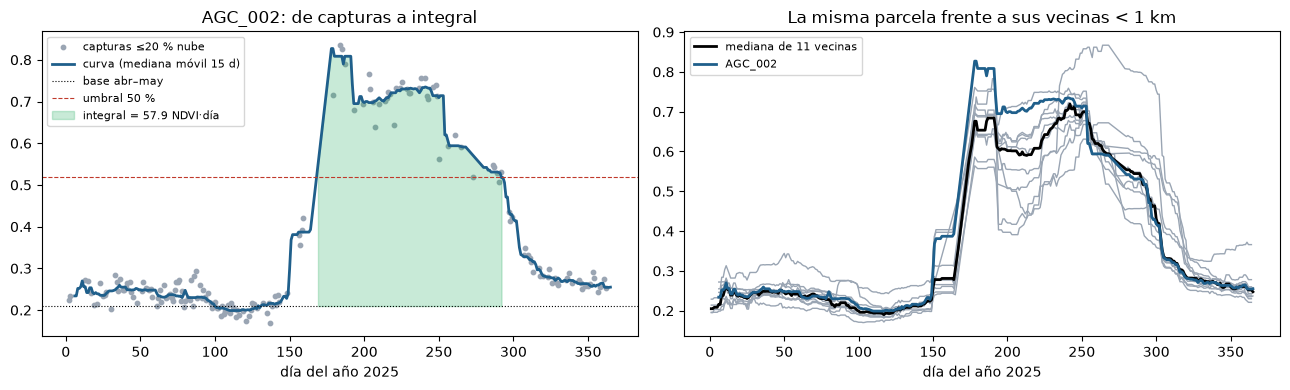

Integral AGC_002: 57.90; mediana de vecinas: 53.11; contraste = +4.79 NDVI·día


In [8]:
DIAS = np.arange(1, 366)


def curva_diaria(capturas, ventana=15, minimo=3):
    # capturas: filas de una parcela con fecha y ndvi_promedio ya filtradas.
    s = capturas.groupby(capturas.fecha.dt.dayofyear).ndvi_promedio.median().reindex(DIAS)
    return s.rolling(ventana, center=True, min_periods=minimo).median().interpolate(limit_area="inside")


def descriptores(c, fin_max=365):
    # Descriptores de la curva c (Serie indexada por día). fin_max=304 corta la curva al 31 de octubre.
    c = c.loc[:fin_max]
    base = c.loc[91:150].median()
    temporada = c.loc[150:min(330, fin_max)]
    pico, dia_pico = temporada.max(), temporada.idxmax()
    umbral = base + 0.5 * (pico - base)
    subida = c.loc[150:dia_pico]
    inicio = subida[subida >= umbral].index.min()
    bajada = c.loc[dia_pico:fin_max]
    fin = bajada[bajada < umbral].index.min() if (bajada < umbral).any() else fin_max
    integral = (c.loc[inicio:fin] - base).clip(lower=0).sum()
    return {"base_abr_may": base, "pico": pico, "dia_pico": dia_pico, "amplitud": pico - base,
            "inicio_verdor": inicio, "fin_verdor": fin, "duracion": fin - inicio, "integral": integral,
            "jul": c.loc[182:212].mean(), "ago": c.loc[213:243].mean(), "sep": c.loc[244:273].mean(),
            "oct": c.loc[274:304].mean(), "nov": c.loc[305:334].mean() if fin_max >= 334 else np.nan,
            "dic": c.loc[335:365].mean() if fin_max >= 365 else np.nan, "ene_mar": c.loc[1:90].mean(),
            "pendiente_senescencia": (c.loc[min(dia_pico + 40, fin_max)] - pico) / 40}


validas = pro[pro.ndvi_promedio.notna() & pro.porcentaje_nubosidad.le(20) & pro.fecha.dt.year.eq(2025)]
CURVAS = {pid: curva_diaria(g) for pid, g in validas.groupby("ID_POLIGONO")}
assert len(CURVAS) == 197
DESC = pd.DataFrame({pid: descriptores(c) for pid, c in CURVAS.items()}).T.astype(float).sort_index()

XY = T[["x_m", "y_m"]].to_numpy()
DIST = np.linalg.norm(XY[:, None] - XY[None], axis=2)
IDS = T.index.to_numpy()


def vecinas(pid, radio):
    i = T.index.get_loc(pid)
    return IDS[(DIST[i] < radio) & (DIST[i] > 0)]


def contraste(serie, radio=1000, minimo=2):
    out = pd.Series(np.nan, index=T.index)
    for pid in T.index:
        v = vecinas(pid, radio)
        if len(v) >= minimo and np.isfinite(serie[pid]):
            out[pid] = serie[pid] - serie[v].median()
    return out


EJEMPLO = next(pid for pid in T.index if len(vecinas(pid, 1000)) >= 2)
c = CURVAS[EJEMPLO]; d = DESC.loc[EJEMPLO]; vv = vecinas(EJEMPLO, 1000)
cap = validas[validas.ID_POLIGONO.eq(EJEMPLO)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(cap.fecha.dt.dayofyear, cap.ndvi_promedio, s=10, color="#9aa5b3", label="capturas ≤20 % nube")
ax[0].plot(DIAS, c, color="#1f5f8b", lw=2, label="curva (mediana móvil 15 d)")
ax[0].axhline(d.base_abr_may, color="k", lw=0.8, ls=":", label="base abr–may")
ax[0].axhline(d.base_abr_may + 0.5 * d.amplitud, color="#c0392b", lw=0.8, ls="--", label="umbral 50 %")
ax[0].fill_between(DIAS, d.base_abr_may, c, where=(DIAS >= d.inicio_verdor) & (DIAS <= d.fin_verdor) & (c > d.base_abr_may),
                   color="#27ae60", alpha=0.25, label=f"integral = {d.integral:.1f} NDVI·día")
ax[0].set_title(f"{EJEMPLO}: de capturas a integral"); ax[0].set_xlabel("día del año 2025"); ax[0].legend(fontsize=8)
for pid in vv:
    ax[1].plot(DIAS, CURVAS[pid], color="#9aa5b3", lw=1)
ax[1].plot(DIAS, pd.DataFrame({p: CURVAS[p] for p in vv}).median(axis=1), color="k", lw=2, label=f"mediana de {len(vv)} vecinas")
ax[1].plot(DIAS, c, color="#1f5f8b", lw=2, label=EJEMPLO)
ax[1].set_title("La misma parcela frente a sus vecinas < 1 km"); ax[1].set_xlabel("día del año 2025"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Integral {EJEMPLO}: {d.integral:.2f}; mediana de vecinas: {DESC.loc[vv, 'integral'].median():.2f}; "
      f"contraste = {d.integral - DESC.loc[vv, 'integral'].median():+.2f} NDVI·día")

In [9]:
Z1000 = contraste(DESC.integral, 1000)
cobertura = pd.DataFrame({"con contraste": Z1000.notna(), "etiquetada": T.y.notna(), "Municipio": T.Municipio})
tabla_cob = cobertura.groupby("Municipio").agg(parcelas=("con contraste", "size"), con_contraste=("con contraste", "sum"))
display(tabla_cob)
N_CON = int(Z1000.notna().sum()); N_CON_L = int(Z1000.loc[L.index].notna().sum()); N_CON_O = int(Z1000.loc[OCULTAS].notna().sum())
print(f"Con contraste: {N_CON}/197 · etiquetadas {N_CON_L}/138 · ocultas {N_CON_O}/59")
assert (N_CON, N_CON_L, N_CON_O) == (158, 108, 50)

# Qué describe la variable, solo con X y las 197 parcelas: correlación con el contraste de cada componente.
COMP = pd.DataFrame({k: contraste(DESC[k], 1000) for k in DESC.columns})
mecanismo = COMP.corr(method="spearman")["integral"].drop("integral").sort_values().round(2)
display(mecanismo.to_frame("Spearman con el contraste de integral (197 parcelas, sin y)"))

,parcelas,con_contraste
Municipio,,
Almoloya,14,9
Apan,1,1
Calpulalpan,44,26
Chignahuapan,100,96
Cuautepec de Hinojosa,9,6
Emiliano Zapata,3,0
Nanacamilpa de Mariano Arista,2,0
Singuilucan,23,20
Tepeapulco,1,0


Con contraste: 158/197 · etiquetadas 108/138 · ocultas 50/59


,"Spearman con el contraste de integral (197 parcelas, sin y)"
inicio_verdor,-0.37
pendiente_senescencia,-0.05
dia_pico,0.05
ene_mar,0.08
base_abr_may,0.09
nov,0.14
fin_verdor,0.15
dic,0.20
oct,0.28
ago,0.38


**Qué significa un contraste alto (solo con X).** Una parcela con más integral que sus
vecinas **reverdece antes** (correlación negativa con el inicio del verdor), está **más
verde en julio**, tiene **mayor pico** y una **temporada más larga**. Es decir, más biomasa
verde y más temprana que su entorno inmediato.

El cuaderno no puede decir por qué ocurre eso en cada parcela. Sin fechas de siembra, manejo
ni visitas, cualquier mecanismo es una hipótesis, no una conclusión.

## 7. El procedimiento: MIX más una corrección con una sola pendiente

Para cada entrenamiento exterior:

1. **Residuos honestos de MIX en el entrenamiento.** Con las cuatro particiones internas
   históricas, cada parcela de entrenamiento recibe una predicción MIX hecha *sin su
   etiqueta*, y su residuo e = y − MIX. (Dentro de muestra, el IDW usaría la propia
   parcela a distancia 0 y el residuo sería casi cero.)
2. **Estandarizar** el contraste con mediana y desviación del entrenamiento: z = (x − med)/sd.
3. **Pendiente penalizada:** β = Σ z·e / (Σ z² + α), con **α = 10 fijo**. Equivale a añadir
   10 observaciones ficticias que dicen β = 0. Con ~85 parcelas con contraste por
   entrenamiento, encoge β alrededor de 10 %.
4. **Predicción:** MIX(validación) + β·z. Si la parcela no tiene contraste, z = 0 y queda MIX.

Las etiquetas de validación no intervienen en ningún paso. Abajo se comprueba con
etiquetas inventadas que cambiarlas no altera la predicción.

In [10]:
RESIDUOS = {}


def residuos_mix(r, f, tr):
    if (r, f) not in RESIDUOS:
        e = pd.Series(np.nan, index=tr)
        for tri, vai in internos(r, f):
            ai, ti = L.loc[tri], L.loc[vai]
            e.loc[vai] = ti.y.to_numpy() - mix(ai, ti)
        assert e.notna().all()
        RESIDUOS[(r, f)] = e
    return RESIDUOS[(r, f)]


def correccion(z, tr, va, e, alpha=10.0):
    x = z.reindex(tr); m = x.notna()
    med, sd = x[m].median(), x[m].std()
    zz = (x[m] - med) / sd
    beta = float((zz * e[m]).sum() / ((zz ** 2).sum() + alpha))
    zv = ((z.reindex(va) - med) / sd).fillna(0.0).to_numpy()
    return beta * zv, beta


BETAS = {}


def candidato(z, alpha=10.0, nombre=None):
    def fn(r, f, a, t):
        c, b = correccion(z, a.index, t.index, residuos_mix(r, f, a.index), alpha)
        if nombre:
            BETAS.setdefault(nombre, []).append(b)
        return mix(a, t) + c
    return fn


# Control de fuga: cambiar las etiquetas de validación no cambia la predicción.
r0, f0, tr0, va0 = SPLITS[0]
p1 = candidato(Z1000)(r0, f0, L.loc[tr0], L.loc[va0])
L_falso = L.copy(); L_falso.loc[va0, "y"] = 99.0
t_falso = L_falso.loc[va0]
assert np.allclose(p1, candidato(Z1000)(r0, f0, L.loc[tr0], t_falso))
# Si ninguna parcela de validación tiene contraste, la predicción es MIX exactamente.
z_val_ausente = Z1000.copy(); z_val_ausente.loc[va0] = np.nan
assert np.array_equal(candidato(z_val_ausente)(r0, f0, L.loc[tr0], L.loc[va0]), mix(L.loc[tr0], L.loc[va0]))
print("Pruebas de fuga y equivalencia superadas.")

Pruebas de fuga y equivalencia superadas.


## 8. Comparación fuera de muestra

Mismas 50 particiones, **SEEN135 principal, FULL138 secundario**, métricas sobre todas las
predicciones OOF sin promediar antes por parcela.

| Procedimiento | Qué cambia frente a MIX | Qué pregunta responde |
| --- | --- | --- |
| **C1 · contraste 1 km** | + β·z con la integral contrastada a 1 km | ¿Aporta H8 con la receta fija? |
| **C2 · selección honesta** | Elige, *dentro de cada entrenamiento*, el contraste más correlacionado con los residuos entre 32 (16 descriptores × 1 y 2 km) | ¿Sobrevive la mejora si la elección que hice viendo etiquetas se repite sin ver la validación? |
| Sin contraste | + β·z con la integral cruda | ¿Importa restar a las vecinas? |
| Sentinel-2, 1 km | Mismo contraste desde otro satélite (predeclarado) | ¿Es Planet o es la parcela? |
| 500 m / 2 km | Otro radio | Sensibilidad, no selección |
| Hasta 31 oct | Curva cortada el 31 de octubre | ¿Depende de usar noviembre–diciembre? |
| α = 0 / α = 30 | Otra penalización | Sensibilidad, no selección |

In [11]:
def curvas_s2():
    s2 = bas[(bas.sensor == "Sentinel-2") & bas.fecha.dt.year.eq(2025) & bas.ndvi_promedio.notna() & bas.porcentaje_nubosidad.le(20)]
    return {pid: curva_diaria(g, ventana=21, minimo=2) for pid, g in s2.groupby("ID_POLIGONO")}


CURVAS_S2 = curvas_s2()
INTEGRAL_S2 = pd.Series({pid: descriptores(c)["integral"] for pid, c in CURVAS_S2.items()}).reindex(T.index)
INTEGRAL_OCT = pd.Series({pid: descriptores(c, fin_max=304)["integral"] for pid, c in CURVAS.items()}).reindex(T.index)

Z = {"C1 · contraste 1 km": Z1000,
     "sin contraste (integral cruda)": DESC.integral,
     "Sentinel-2 · contraste 1 km": contraste(INTEGRAL_S2, 1000),
     "contraste 500 m": contraste(DESC.integral, 500),
     "contraste 2 km": contraste(DESC.integral, 2000),
     "contraste 1 km hasta 31 oct": contraste(INTEGRAL_OCT, 1000)}
NB32 = pd.concat([pd.DataFrame({f"{k}_{R}": contraste(DESC[k], R) for k in DESC.columns}) for R in (1000, 2000)], axis=1)
ELECCIONES_C2 = []


def seleccion_honesta(M):
    def fn(r, f, a, t):
        e = residuos_mix(r, f, a.index)
        X_ = M.loc[a.index]
        fuerza = {c: abs(spearmanr(X_[c][X_[c].notna()], e[X_[c].notna()])[0]) for c in M.columns}
        mejor = max(fuerza, key=fuerza.get)
        ELECCIONES_C2.append(mejor)
        return mix(a, t) + correccion(M[mejor], a.index, t.index, e)[0]
    return fn


modelos = {"MUN": lambda r, f, a, t: mun_pred(a, t), "MIX": lambda r, f, a, t: mix(a, t)}
modelos.update({k: candidato(z, nombre=k) for k, z in Z.items()})
modelos["C2 · selección honesta"] = seleccion_honesta(NB32)
modelos["C1 · α = 0"] = candidato(Z1000, alpha=0.0)
modelos["C1 · α = 30"] = candidato(Z1000, alpha=30.0)
OOF = evaluar(modelos)
R = resumen(OOF)
display(R.round(4).sort_values(["escenario", "RMSE"]))
print("Variable elegida por C2 en los 50 entrenamientos:", pd.Series(ELECCIONES_C2).value_counts().to_dict())
b = pd.Series(BETAS["C1 · contraste 1 km"])
print(f"β de C1 (t/ha por desviación estándar): media {b.mean():+.3f}, rango [{b.min():+.3f}, {b.max():+.3f}], negativa en {(b < 0).sum()}/50")

S = "SEEN135"
assert abs(R.loc[(S, "contraste 1 km hasta 31 oct"), "RMSE"] - R.loc[(S, "C1 · contraste 1 km"), "RMSE"]) < 5e-4
assert abs(R.loc[(S, "C1 · contraste 1 km"), "RMSE"] - 0.48170) < 2e-4
assert R.loc[(S, "C2 · selección honesta"), "RMSE"] < R.loc[(S, "MIX"), "RMSE"]
assert R.loc[(S, "Sentinel-2 · contraste 1 km"), "RMSE"] < R.loc[(S, "MIX"), "RMSE"]

n_oof    RMSE     MAE      R2  reps RMSE<MIX  reps MAE<MIX  RMSE Chignahuapan  RMSE resto
escenario modelo                                                                                                                   
FULL138   Sentinel-2 · contraste 1 km      1380  0.4865  0.3375  0.6709             10            10             0.5597      0.3943
          C1 · α = 30                      1380  0.4875  0.3387  0.6695             10            10             0.5680      0.3842
          contraste 1 km hasta 31 oct      1380  0.4875  0.3394  0.6695             10            10             0.5681      0.3842
          C1 · contraste 1 km              1380  0.4876  0.3396  0.6694             10             8             0.5679      0.3846
          C1 · α = 0                       1380  0.4879  0.3403  0.6690             10             7             0.5680      0.3853
          C2 · selección honesta           1380  0.4890  0.3410  0.6675              9             6             0.5687      0.3871
          contraste 2 km                   1380  0.4919  0.3426  0.6635             10             4             0.5730      0.3880
          contraste 500 m                  1380  0.4924  0.3429  0.6628             10             2             0.5734      0.3887
          sin contraste (integral cruda)   1380  0.4932  0.3425  0.6618              9             3             0.5723      0.3923
          MIX                              1380  0.4938  0.3417  0.6609              0             0             0.5736      0.3920
          MUN                              1380  0.5118  0.3354  0.6359              0            10             0.5902      0.4127
SEEN135   Sentinel-2 · contraste 1 km      1350  0.4806  0.3311  0.6751             10             8             0.5597      0.3736
          C1 · α = 30                      1350  0.4815  0.3322  0.6738             10             8             0.5680      0.3620
          contraste 1 km hasta 31 oct      1350  0.4816  0.3330  0.6737             10             7             0.5681      0.3623
          C1 · contraste 1 km              1350  0.4817  0.3333  0.6735             10             7             0.5679      0.3629
          C1 · α = 0                       1350  0.4821  0.3341  0.6729             10             6             0.5680      0.3639
          C2 · selección honesta           1350  0.4831  0.3347  0.6716              7             4             0.5687      0.3656
          contraste 2 km                   1350  0.4855  0.3357  0.6683             10             2             0.5730      0.3648
          sin contraste (integral cruda)   1350  0.4859  0.3345  0.6679              9             3             0.5723      0.3668
          contraste 500 m                  1350  0.4863  0.3361  0.6672              9             1             0.5734      0.3663
          MIX                              1350  0.4872  0.3342  0.6660              0             0             0.5736      0.3683
          MUN                              1350  0.4934  0.3213  0.6575              1            10             0.5902      0.3565

Variable elegida por C2 en los 50 entrenamientos: {'integral_1000': 47, 'jul_1000': 1, 'base_abr_may_1000': 1, 'amplitud_1000': 1}
β de C1 (t/ha por desviación estándar): media -0.096, rango [-0.137, -0.054], negativa en 50/50


**Lectura de la tabla.**

* **C1 baja el RMSE de MIX de 0.4872 a ≈0.4817 en SEEN135** (≈1.1 %) y de 0.4938 a ≈0.4876
  en FULL138. Gana en las 10 repeticiones en ambos escenarios. El MAE queda prácticamente
  igual que el de MIX, todavía por encima del de MUN.
* **La pendiente es negativa en las 50 particiones.** Una parcela más verde y más temprana
  que sus vecinas tiende a rendir *menos* de lo que predice el territorio. El signo es
  estable, pero no es el que daría una lectura ingenua de "más verde = más grano".
* **C2 conserva unas tres cuartas partes de la mejora** (≈0.483 en SEEN) aunque repite la
  búsqueda dentro de cada entrenamiento; gana en 7/10 repeticiones. Elige la integral a 1 km en casi todas las particiones: la elección no
  fue un accidente de la muestra completa.
* **Sin contraste, la misma integral casi no ayuda.** Lo informativo es la diferencia con las
  vecinas, no el nivel absoluto. Es justo lo que predice H8 y explica por qué las medias de
  las rondas anteriores no funcionaron.
* **Sentinel-2, otro satélite y otra resolución, da una mejora del mismo tamaño o mayor.**
  La réplica estaba predeclarada. No es una prueba independiente, porque las etiquetas son
  las mismas, pero descarta que sea un artefacto de Planet.
* **500 m y 2 km mejoran menos.** A 500 m faltan vecinas; a 2 km las vecinas ya no comparten
  lo que muestra el variograma. **Cortar la curva el 31 de octubre conserva toda la
  mejora:** la información no depende de noviembre–diciembre, y esa versión evita discutir
  su admisibilidad.

In [12]:
def regla(oof, cand):
    o = oof[oof.visto].assign(e=lambda d: d.pred - d.obs)
    rm = o.groupby(["modelo", "rep"]).e.apply(lambda s: np.sqrt((s ** 2).mean())).unstack()
    ma = o.groupby(["modelo", "rep"]).e.apply(lambda s: s.abs().mean()).unstack()
    g = o.groupby("modelo").e
    rmse, mae = np.sqrt(g.apply(lambda s: (s ** 2).mean())), g.apply(lambda s: s.abs().mean())
    return pd.Series({
        "RMSE<MIX agrupado": rmse[cand] < rmse["MIX"], "RMSE<MIX en reps": int((rm.loc[cand] < rm.loc["MIX"]).sum()),
        "MAE≤MUN agrupado": mae[cand] <= mae["MUN"], "MAE≤MUN en reps": int((ma.loc[cand] <= ma.loc["MUN"]).sum()),
        "MAE≤MIX agrupado": mae[cand] <= mae["MIX"], "MAE≤MIX en reps": int((ma.loc[cand] <= ma.loc["MIX"]).sum())})


display(pd.DataFrame({c: regla(OOF, c) for c in ["C1 · contraste 1 km", "C2 · selección honesta", "Sentinel-2 · contraste 1 km"]}))

,C1 · contraste 1 km,C2 · selección honesta,Sentinel-2 · contraste 1 km
RMSE<MIX agrupado,True,True,True
RMSE<MIX en reps,10,7,10
MAE≤MUN agrupado,False,False,False
MAE≤MUN en reps,0,0,0
MAE≤MIX agrupado,True,False,True
MAE≤MIX en reps,7,4,8


**Frente a las reglas del proyecto (SEEN135).** La regla histórica pide RMSE < MIX y
MAE ≤ MUN, agrupados y en ≥8/10 repeticiones. C1 cumple la parte de RMSE con holgura,
pero **no la de MAE frente a MUN**, igual que todos los candidatos anteriores. La regla
propuesta en el plan de EXP_07 (MAE ≤ MIX) queda en el límite; la tabla muestra el conteo
exacto. Bajo cualquiera de las dos, C1 es **candidato con reservas**, no un ganador
automático.

## 9. ¿Podría ser azar? Dos nulos por permutación del procedimiento completo

Un solo candidato que mejora a MIX no basta: cualquier variable añade algo de ajuste.
Repetimos **el procedimiento entero** con variables sin relación con el rendimiento,
permutando el contraste entre parcelas del mismo municipio (se conservan su distribución
y sus faltantes):

* **Nulo de C1:** permutar el contraste de 1 km `N_PERM_C1` veces.
* **Nulo de C2:** permutar *juntas* las 32 columnas (misma permutación de filas) y repetir
  la selección dentro de cada entrenamiento `N_PERM_C2` veces. Este nulo descuenta haber
  elegido la mejor entre 32.

El p-valor es la fracción de permutaciones que igualan o superan el RMSE de C1/C2. Es una
calibración del procedimiento, no una prueba confirmatoria, porque el diseño se fijó
después de explorar.

**Presupuesto de esta ejecución.** Comparación principal: 10 procedimientos × 50
particiones; los residuos internos de MIX se calculan una vez (200 entrenamientos
internos). Nulos: 50 × (N_PERM_C1 + N_PERM_C2) correcciones lineales adicionales. El GP y MIX
afinado de la sección 4 suman 100 ajustes GP y 50 × 4 × 12 evaluaciones internas de MIX.

,observado SEEN,nulo: media SEEN,nulo: percentil 5 SEEN,p SEEN,p FULL
C1 (receta fija),0.4817,0.4894,0.4845,0.03,0.015
C2 (selección entre 32),0.4831,0.4938,0.4837,0.05,0.050


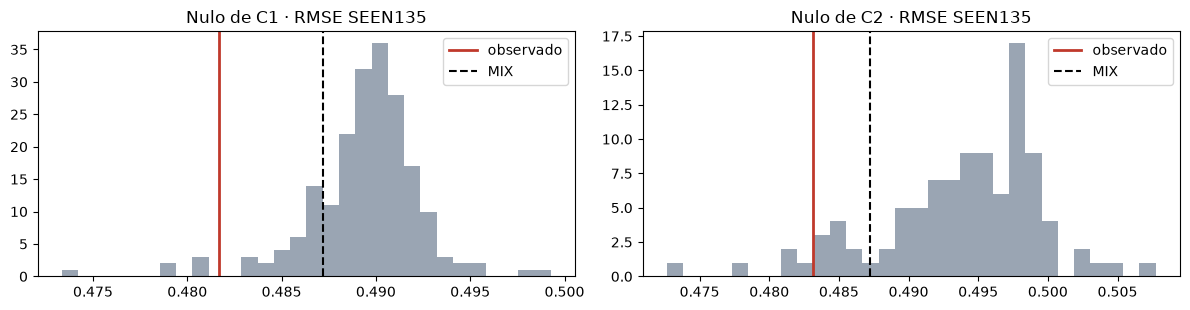

In [13]:
BASE = {}
for r, f, tr, va in SPLITS:
    a, t = L.loc[tr], L.loc[va]
    BASE[(r, f)] = (mix(a, t), t.y.to_numpy(), t.Municipio.isin(set(a.Municipio)).to_numpy(), residuos_mix(r, f, tr), tr, va)


def rmse_proc(z=None, M=None):
    se, vis = [], []
    for k, (base, yv, visto, e, tr, va) in BASE.items():
        if M is not None:
            X_ = M.loc[tr]
            z = M[max(M.columns, key=lambda c: abs(spearmanr(X_[c][X_[c].notna()], e[X_[c].notna()])[0]))]
        se.append((base + correccion(z, tr, va, e)[0] - yv) ** 2); vis.append(visto)
    se, vis = np.concatenate(se), np.concatenate(vis)
    return np.sqrt(se[vis].mean()), np.sqrt(se.mean())


def permutar_filas(obj, rng):
    out = obj.copy()
    for _, g in T.groupby("Municipio"):
        idx = g.index.to_numpy()
        out.loc[idx] = obj.loc[rng.permutation(idx)].to_numpy()
    return out


rng = np.random.default_rng(SEMILLA)
obs_c1, obs_c2 = rmse_proc(z=Z1000), rmse_proc(M=NB32)
nulo_c1 = np.array([rmse_proc(z=permutar_filas(Z1000, rng)) for _ in range(N_PERM_C1)])
nulo_c2 = np.array([rmse_proc(M=permutar_filas(NB32, rng)) for _ in range(N_PERM_C2)])
mix_seen = R.loc[("SEEN135", "MIX"), "RMSE"]
NULOS = pd.DataFrame({
    "observado SEEN": [obs_c1[0], obs_c2[0]], "nulo: media SEEN": [nulo_c1[:, 0].mean(), nulo_c2[:, 0].mean()],
    "nulo: percentil 5 SEEN": [np.quantile(nulo_c1[:, 0], .05), np.quantile(nulo_c2[:, 0], .05)],
    "p SEEN": [(nulo_c1[:, 0] <= obs_c1[0]).mean(), (nulo_c2[:, 0] <= obs_c2[0]).mean()],
    "p FULL": [(nulo_c1[:, 1] <= obs_c1[1]).mean(), (nulo_c2[:, 1] <= obs_c2[1]).mean()]},
    index=["C1 (receta fija)", "C2 (selección entre 32)"])
display(NULOS.round(4))
assert NULOS.loc["C1 (receta fija)", "p SEEN"] <= 0.05 and NULOS.loc["C2 (selección entre 32)", "p SEEN"] <= 0.10
assert (NULOS["nulo: media SEEN"] > mix_seen).all()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
for a_, nulo, obs, tit in [(ax[0], nulo_c1, obs_c1, "C1"), (ax[1], nulo_c2, obs_c2, "C2")]:
    a_.hist(nulo[:, 0], bins=30, color="#9aa5b3"); a_.axvline(obs[0], color="#c0392b", lw=2, label="observado")
    a_.axvline(mix_seen, color="k", ls="--", label="MIX"); a_.set_title(f"Nulo de {tit} · RMSE SEEN135"); a_.legend()
plt.tight_layout(); plt.show()

**Resultado.** Con variables permutadas, la corrección **empeora** MIX en promedio: añadir
una pendiente sin información cuesta error. **C1 queda en la cola izquierda del nulo
(p ≈ 0.03).** **C2**, que descuenta la selección entre 32 columnas, queda **en el borde
(p ≈ 0.05)**; es la cifra más honesta de las dos. Con 100 permutaciones, ese p-valor tiene
una resolución de ±0.02: es evidencia débil, no concluyente.

Ninguno de los dos nulos descuenta **mi exploración previa a este diseño**: la elección de
H8 tras el barrido del bloque B y el radio de 1 km. Son evidencia de desarrollo, no
confirmación independiente.

## 10. ¿Dónde está la mejora? Territorio y concentración

La lección de las rondas anteriores es que una mejora pequeña puede depender de dos o tres
parcelas. Lo comprobamos sin quitar parcelas del entrenamiento: solo reorganizamos los
errores ya calculados.

In [14]:
o = OOF[OOF.visto & OOF.modelo.isin(["MIX", "C1 · contraste 1 km"])]
w = o.pivot_table(index=["ID_POLIGONO", "rep"], columns="modelo", values="pred").join(o.groupby(["ID_POLIGONO", "rep"]).obs.first())
w["dSE"] = (w["C1 · contraste 1 km"] - w.obs) ** 2 - (w["MIX"] - w.obs) ** 2
por_parcela = w.groupby("ID_POLIGONO").dSE.sum().sort_values()
total = por_parcela.sum()
conc = pd.Series({"cambio neto de SSE (negativo = mejora)": total,
                  "parcelas que mejoran": int((por_parcela < 0).sum()), "parcelas que empeoran": int((por_parcela > 0).sum()),
                  "sin las 2 más favorecidas": por_parcela.iloc[2:].sum(), "sin las 5 más favorecidas": por_parcela.iloc[5:].sum()})
display(conc.round(3).to_frame("C1 frente a MIX, SEEN135"))
assert total < 0 and por_parcela.iloc[2:].sum() < 0 < por_parcela.iloc[5:].sum()
extremos = pd.concat([por_parcela.head(6), por_parcela.tail(4)]).to_frame("ΔSSE (10 reps)").join(L[["Municipio", "y"]]).join(Z1000.rename("contraste"))
display(extremos.round(3))

,"C1 frente a MIX, SEEN135"
cambio neto de SSE (negativo = mejora),-7.190
parcelas que mejoran,60.000
parcelas que empeoran,47.000
sin las 2 más favorecidas,-1.405
sin las 5 más favorecidas,3.681


,ΔSSE (10 reps),Municipio,y,contraste
ID_POLIGONO,,,,
AGC_162,-3.465,Chignahuapan,5.59,-22.177
AGC_172,-2.321,Chignahuapan,5.19,-18.253
AGC_024,-1.974,Chignahuapan,3.03,9.452
AGC_133,-1.582,Chignahuapan,3.91,11.396
AGC_034,-1.529,Singuilucan,2.00,6.437
AGC_041,-1.522,Singuilucan,2.50,14.901
AGC_014,1.343,Chignahuapan,4.83,10.961
AGC_062,2.035,Chignahuapan,3.81,-11.562
AGC_015,2.490,Chignahuapan,2.64,-5.769


**Resultado: la mejora existe, pero está concentrada.** Mejoran algo más parcelas de las que
empeoran. **Sin las dos más favorecidas, queda alrededor de una quinta parte de la ganancia;
sin las cinco, se invierte.** Las favorecidas van en ambas direcciones, como predice H8.
Dos parcelas de rendimiento alto, menos verdes que sus vecinas (AGC_162, AGC_172), suben.
Cuatro de rendimiento bajo, más verdes que sus vecinas (AGC_024, AGC_133, AGC_034,
AGC_041), bajan. Las dos de rendimiento más bajo de Chignahuapan (AGC_171, AGC_015)
empeoran. Son menos verdes que sus vecinas y su rendimiento no se ve en el verdor, como ya
había mostrado el diagnóstico del 24 de septiembre.

Esto pesa más que el p-valor. **La mejora en RMSE es real dentro de esta muestra, pero
estrecha.** El RMSE de las 59 ocultas puede moverse por el azar de qué parcelas tocaron en
ese conjunto.

## 11. Las 59 parcelas ocultas: soporte, sin predecirlas

No generamos predicciones de entrega. Solo comprobamos si la variable existe y está en el
rango observado en las etiquetadas.

In [15]:
zl, zo = Z1000.loc[L.index].dropna(), Z1000.loc[OCULTAS]
soporte = pd.DataFrame({"Municipio": T.loc[OCULTAS, "Municipio"], "tiene_contraste": zo.notna(),
                        "dentro_rango_etiquetadas": zo.between(zl.min(), zl.max())})
display(soporte.groupby("Municipio")[["tiene_contraste", "dentro_rango_etiquetadas"]].sum().join(soporte.groupby("Municipio").size().rename("ocultas")))
print(f"Rango del contraste: etiquetadas [{zl.min():.1f}, {zl.max():.1f}] · ocultas con valor [{zo.min():.1f}, {zo.max():.1f}]")
b_med = pd.Series(BETAS["C1 · contraste 1 km"]).mean()
print(f"Corrección típica (|β|·|z|) en ocultas con contraste: mediana {np.nanmedian(np.abs(b_med * (zo - zl.median()) / zl.std())):.3f} t/ha")
print(f"Tiempo total de ejecución: {(time.time() - T0) / 60:.1f} min")

,tiene_contraste,dentro_rango_etiquetadas,ocultas
Municipio,,,
Almoloya,3,3,4
Calpulalpan,9,9,14
Chignahuapan,29,28,29
Cuautepec de Hinojosa,3,3,4
Nanacamilpa de Mariano Arista,0,0,1
Singuilucan,6,6,7


Rango del contraste: etiquetadas [-36.7, 18.6] · ocultas con valor [-14.2, 26.4]
Corrección típica (|β|·|z|) en ocultas con contraste: mediana 0.044 t/ha
Tiempo total de ejecución: 4.5 min


## 12. Decisión, límites y recomendación

**Respuesta a la pregunta.** El contraste vecinal de la integral de verdor es la **única
señal satelital encontrada hasta ahora que pasa todos estos filtros a la vez**:

* sobrevive a repetir su selección dentro de cada entrenamiento;
* supera el nulo por permutación con receta fija (p ≈ 0.03) y queda en el borde
  (p ≈ 0.05) cuando también se descuenta la selección;
* se replica con otro satélite, con la réplica predeclarada;
* se mantiene si la curva se corta el 31 de octubre;
* deja de funcionar si se quita el contraste;
* su pendiente tiene el mismo signo en las 50 particiones.

Su efecto es **pequeño (≈1 % de RMSE) y concentrado en pocas parcelas**, y no cumple la
regla histórica de MAE.

**Qué recomienda este cuaderno al equipo:**

1. **Cerrar la búsqueda de agregados.** El bloque B muestra que más columnas del mismo tipo
   tienen un retorno esperado bajo. Esto incluye otros índices, ventanas, estadísticas o
   umbrales de nube.
2. **Si se hace una ronda más, que sea esta, ratificada antes de ajustar:** C1 con la receta
   de este cuaderno (sin cambiar radio, variable ni α). Se sugiere la versión **cortada al 31
   de octubre**: rinde igual en estos datos y elimina la discusión sobre usar
   noviembre–diciembre. Esa elección se hace aquí, a la vista, y debe registrarse así. Usar particiones nuevas como
   comprobación de robustez, sin sustituir las históricas, y decidir con la regla elegida de
   antemano. Con el plazo del 19 de octubre, después de eso: congelar.
3. **Para la entrega**, el equipo decide entre MIX y MIX + C1 según la métrica oficial que
   confirme FIRA. Con RMSE/R², C1 tiene ventaja esperada pequeña y riesgo acotado: la
   corrección mediana en las ocultas es de ≈0.04 t/ha y deja MIX intacto donde no hay vecinas. Con MAE, MUN
   sigue siendo mejor que ambos.
4. **Para el jurado**, la respuesta defendible a "¿qué variable satelital importa?" es: *el
   territorio explica la mayor parte; el satélite absoluto no añade información
   distinguible del azar; solo la diferencia de verdor con las vecinas aporta algo, con signo
   negativo.* Es un hallazgo honesto e interesante, no una debilidad.

**Límites que deben acompañar cualquier uso:**

* El diseño se fijó después de explorar con las mismas 138 etiquetas. Las cifras son de
  desarrollo, no una confirmación independiente.
* La receta principal usa noviembre–diciembre para cerrar la temporada en parcelas tardías.
  La versión al 31 de octubre da el mismo resultado (sección 8).
* El signo negativo no tiene mecanismo verificado: maleza temprana, exceso vegetativo y
  acame, o fecha de siembra distinta son hipótesis compatibles, no conclusiones.
* 9 de las 59 ocultas no tienen contraste y reciben MIX sin cambios. Nanacamilpa conserva su
  limitación de una sola etiqueta.

## Referencias (APA 7)

Druckenmiller, H., & Hsiang, S. (2018). *Accounting for unobservable heterogeneity in cross
section using spatial first differences* (Working Paper No. 25177). National Bureau of
Economic Research. https://doi.org/10.3386/w25177

Jönsson, P., & Eklundh, L. (2004). TIMESAT—a program for analyzing time-series of satellite
sensor data. *Computers & Geosciences, 30*(8), 833–845. https://doi.org/10.1016/j.cageo.2004.05.006

Rasmussen, M. S. (1992). Assessment of millet yields and production in northern Burkina Faso
using integrated NDVI from the AVHRR. *International Journal of Remote Sensing, 13*(18),
3431–3442. https://doi.org/10.1080/01431169208904132

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent
selection bias in performance evaluation. *Journal of Machine Learning Research, 11*,
2079–2107. https://jmlr.org/papers/v11/cawley10a.html

Varoquaux, G. (2018). Cross-validation failure: Small sample sizes lead to large error bars.
*NeuroImage, 180*, 68–77. https://doi.org/10.1016/j.neuroimage.2017.06.061